# Llenado de una pieza inyectada en 3D: animaciones y análisis del proceso

Este cuaderno simula el **llenado de una pieza de plástico inyectada**, una caja abierta con nervios y un agujero, y analiza el proceso como se
hace al diseñar un molde: patrón de llenado, equilibrio entre zonas, **líneas de soldadura**, posibles **atrapamientos de aire**, presión de
inyección, **fuerza de cierre**, enfriamiento y capa congelada, y la **ventana de proceso** en función del tiempo de llenado.

**El modelo.** La pieza es delgada, así que el fundido avanza por su **superficie media** y, en cada punto, el flujo a través del espesor es el
de un canal entre dos placas (aproximación de **Hele-Shaw**, el modo *midplane* de los programas de inyección). La superficie media es una malla
de triángulos en 3D: la base, las paredes y los nervios son placas unidas por sus aristas, cada una con su espesor. Cada nodo lleva además un
perfil de temperatura en el espesor: el molde frío enfría el fundido, y la capa que baja de la temperatura de no flujo se congela y estrecha el
paso. Es el módulo `Source/Physics/HeleShaw.py` sobre una superficie en el espacio (fase 6 de `docs/PLAN_3D.md`).

**Limitaciones.** No se resuelve el flujo a través del espesor (zonas gruesas, uniones con radio, el efecto fuente del frente), las uniones de
placas no tienen pérdida propia y no hay medidas de esta pieza con que comparar: los números ilustran el método y las tendencias, no son una
predicción validada de una pieza real.

Tiempo de cálculo: unos 10 minutos en total (el llenado principal, unos 3 minutos; el barrido de la ventana de proceso, el resto).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from mpl_toolkits.mplot3d.art3d import Poly3DCollection, Line3DCollection
from IPython.display import HTML
import gmsh

from Source.Pre_processing.Mesh import Mesh
from Source.Physics.HeleShaw import HeleShawFilling
from Source.Physics.Rheology import CrossWLF
from Source.Simulation.Discretization import Discretization

plt.rcParams['animation.embed_limit'] = 60          # MB para las animaciones incrustadas

# Pieza: caja abierta de 120 x 80 x 25 mm
Lx, Ly, Lz = 0.120, 0.080, 0.025
GATE = (0.060, 0.040, 0.002)          # entrada puntual en el centro de la base (un agujero de 2 mm de radio, su borde es la entrada)
HOLE = (0.030, 0.040, 0.006)          # agujero de 6 mm de radio en la base
RIBS = (0.027, 0.053)                 # dos nervios a lo largo de x, en estas y
RIB_X0, RIB_X1, RIB_H = 0.020, 0.100, 0.012
H_BASE, H_WALL, H_RIB = 2.0e-3, 1.6e-3, 1.2e-3     # espesores [m]
SIZE = 5e-3                                         # tamano de elemento [m]

# Proceso y material: POLYFORT FPP 30 GFC K1079 (PP + 30 % de fibra de vidrio)
T_MELT, T_MOLD = 230.0, 50.0                        # fundido y molde [C]
RHO, CP, K, HTC = 970.0, 2000.0, 0.22, 5000.0       # densidad, calor especifico, conductividad, contacto con el molde [W/m2K]
T_NOFLOW = 453.9 - 273.15                           # temperatura de no flujo: la b5 del ajuste de Tait del mismo material [C]
FILL_TIME = 1.0                                     # tiempo de llenado objetivo [s] (caudal constante)
LAW = CrossWLF(n=0.2619, tau_star=1.778e4, D1=4.378e17, D2=266.7, A1=39.22, A2=51.6, gamma_min=1e-2)

## El material

Ley **Cross–WLF** ajustada a la curva de viscosidad de la ficha técnica (`Source/Physics/Fitting.py`). La viscosidad cae con la tasa de corte
(adelgazamiento, $n = 0.26$) y sube mucho al enfriarse: entre 260 y 200 °C se multiplica por varias veces. La línea punteada es la temperatura de
**no flujo**: por debajo, el modelo considera congelado el fundido.

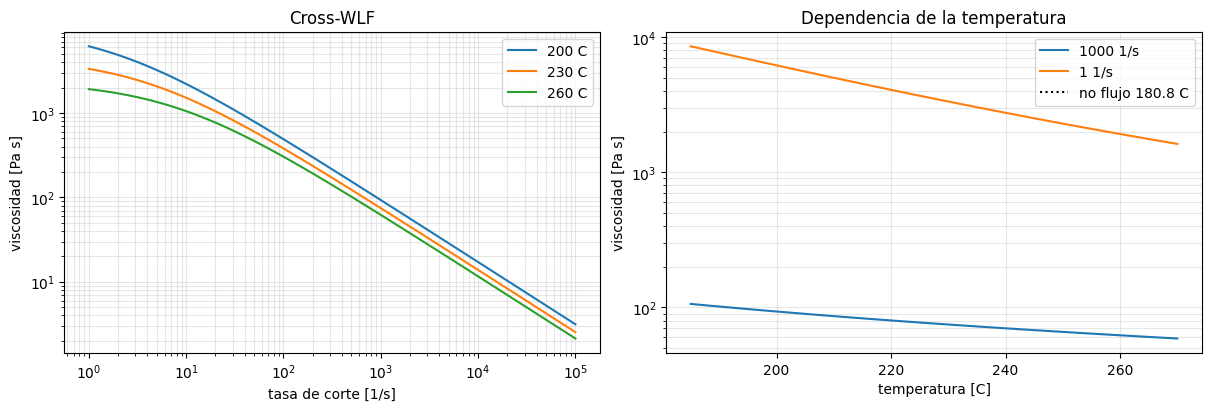

In [2]:
rates = np.logspace(0, 5, 100)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for T in (200.0, 230.0, 260.0):
    axes[0].loglog(rates, np.asarray(LAW(rates ** 2, T)), label=f'{T:.0f} C')
axes[0].set_xlabel('tasa de corte [1/s]'); axes[0].set_ylabel('viscosidad [Pa s]'); axes[0].grid(True, which='both', alpha=0.3)
axes[0].legend(); axes[0].set_title('Cross-WLF')
temps = np.linspace(185.0, 270.0, 100)
axes[1].semilogy(temps, np.asarray(LAW(np.full(temps.shape, 1e6), temps)), label='1000 1/s')
axes[1].semilogy(temps, np.asarray(LAW(np.full(temps.shape, 1.0), temps)), label='1 1/s')
axes[1].axvline(T_NOFLOW, ls=':', color='k', label=f'no flujo {T_NOFLOW:.1f} C')
axes[1].set_xlabel('temperatura [C]'); axes[1].set_ylabel('viscosidad [Pa s]'); axes[1].grid(True, which='both', alpha=0.3)
axes[1].legend(); axes[1].set_title('Dependencia de la temperatura')
plt.show()

## La geometría y su superficie media

Se construye con gmsh: una caja sin tapa (base y cuatro paredes), dos nervios verticales sobre la base, un agujero en la base y la entrada
puntual en el centro. `fragment` hace la malla conforme: los nervios comparten nodos con la base a lo largo de su unión, una **unión en T**
donde tres placas comparten cada arista. `Mesh.from_gmsh_model(surface=True)` conserva las tres coordenadas.

2304 triangulos, 1209 nodos; entrada en 8 aristas


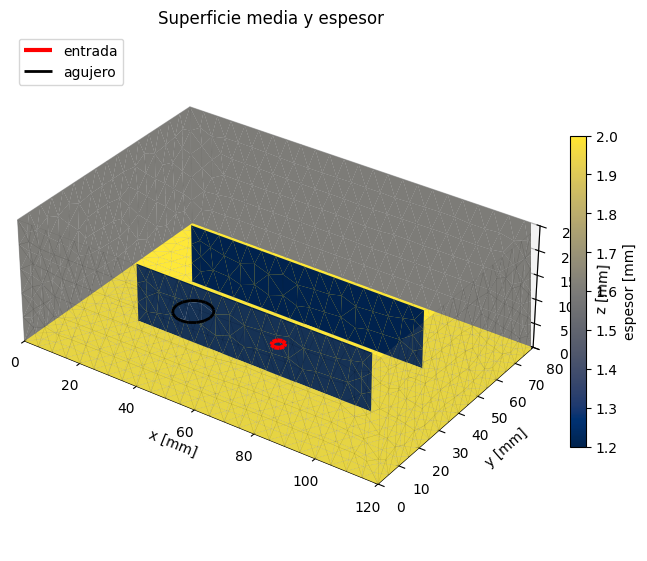

In [3]:
gmsh.initialize()
gmsh.option.setNumber("General.Terminal", 0)
try:
    occ = gmsh.model.occ
    box = occ.addBox(0, 0, 0, Lx, Ly, Lz)
    occ.synchronize()
    faces = [t for _, t in gmsh.model.getEntities(2)]
    lid = [s for s in faces if abs(occ.getCenterOfMass(2, s)[2] - Lz) < 1e-12]
    base = [s for s in faces if abs(occ.getCenterOfMass(2, s)[2]) < 1e-12][0]
    occ.remove([(3, box)])                                   # quedan las caras; se quita la tapa
    occ.remove([(2, s) for s in lid])
    occ.cut([(2, base)], [(2, occ.addDisk(x, y, 0, r, r)) for x, y, r in (GATE, HOLE)])
    for y in RIBS:
        rib = occ.addRectangle(RIB_X0, 0.0, 0.0, RIB_X1 - RIB_X0, RIB_H)     # en z = 0, luego de pie en y
        occ.rotate([(2, rib)], 0, 0, 0, 1, 0, 0, np.pi / 2)
        occ.translate([(2, rib)], 0, y, 0)
    occ.synchronize()
    occ.fragment([(2, t) for _, t in gmsh.model.getEntities(2)], [])
    occ.synchronize()
    gmsh.option.setNumber('Mesh.MeshSizeMax', SIZE)
    gmsh.option.setNumber('Mesh.MeshSizeMin', SIZE / 3)
    gmsh.option.setNumber('Mesh.MeshSizeFromCurvature', 16)          # 16 elementos por vuelta en el agujero y la entrada
    gmsh.model.mesh.generate(2)
    mesh = Mesh.from_gmsh_model(surface=True)
finally:
    gmsh.finalize()


def gap(x, y, z):
    on_rib = np.zeros(np.shape(x), dtype=bool)
    for yr in RIBS:
        on_rib |= (np.abs(y - yr) < 1e-9) & (z > 1e-9)
    return np.where(on_rib, H_RIB, np.where(z < 1e-9, H_BASE, H_WALL))


xyz = np.array([n.coor for n in mesh.NL])
tris = np.array([e.getNodesId() for e in mesh.EL])
centres = xyz[tris].mean(axis=1)
h_elem = gap(*centres.T)
zone = np.where(h_elem == H_RIB, 'nervio', np.where(centres[:, 2] < 1e-9, 'base', 'pared'))
h_node = gap(*xyz.T)
zone_of_node = lambda k: 'nervio' if h_node[k] == H_RIB else ('base' if xyz[k, 2] < 1e-9 else 'pared')
gate = mesh.boundary_facets(lambda x, y, z: z < 1e-9 and np.hypot(x - GATE[0], y - GATE[1]) < GATE[2] + 1e-6)
print(f"{mesh.getNoE()} triangulos, {mesh.getNoN()} nodos; entrada en {len(gate)} aristas")


def draw_part(ax, face_values, cmap='viridis', norm=None, empty=None, title=None, edges=False):

    # La pieza en 3D: cada triangulo con el color de su valor; los vacios (empty) en gris; las paredes y = 0 y x = Lx, que miran al
    # observador, casi transparentes para ver el interior.
    cmap = plt.get_cmap(cmap)
    norm = norm or plt.Normalize(np.nanmin(face_values), np.nanmax(face_values))
    colours = cmap(norm(np.nan_to_num(face_values, nan=norm.vmin)))
    if empty is not None:
        colours[empty] = (0.85, 0.85, 0.85, 1.0)
    front = (centres[:, 1] < 1e-9) | (centres[:, 0] > Lx - 1e-9)
    colours[front, 3] = 0.18
    ax.add_collection3d(Poly3DCollection(xyz[tris] * 1e3, facecolors=colours,
                                         edgecolors=(0, 0, 0, 0.12 if edges else 0.04), linewidths=0.2))
    ax.computed_zorder = False                                       # what is drawn after the surface stays on top of it
    ax.set_xlim(0, Lx * 1e3); ax.set_ylim(0, Ly * 1e3); ax.set_zlim(0, Lz * 1e3)
    ax.set_box_aspect((Lx, Ly, Lz * 1.6))
    ax.view_init(elev=32, azim=-55)
    ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]'); ax.set_zlabel('z [mm]')
    if title:
        ax.set_title(title)
    return plt.cm.ScalarMappable(norm=norm, cmap=cmap)


fig = plt.figure(figsize=(9, 5.5), constrained_layout=True)
ax = fig.add_subplot(projection='3d')
sm = draw_part(ax, h_elem * 1e3, cmap='cividis', title='Superficie media y espesor', edges=True)
hole_edges = mesh.boundary_facets(lambda x, y, z: z < 1e-9 and np.hypot(x - HOLE[0], y - HOLE[1]) < HOLE[2] + 1e-6)
ax.add_collection3d(Line3DCollection(xyz[np.array(gate)] * 1e3, colors='r', linewidths=3, label='entrada', zorder=10))
ax.add_collection3d(Line3DCollection(xyz[np.array(hole_edges)] * 1e3, colors='k', linewidths=2, label='agujero', zorder=10))
ax.legend(loc='upper left')
fig.colorbar(sm, ax=ax, shrink=0.6, label='espesor [mm]')
plt.show()

## El llenado

Caudal constante para llenar la cavidad en `FILL_TIME`. El fundido entra a 230 °C en un molde a 50 °C. `fill()` avanza **nodo a nodo**
(volúmenes de control): en cada paso resuelve la presión del fundido, $\nabla\cdot(S\,\nabla p) = 0$ con la fluidez del espesor $S$ (que depende de
la temperatura y del adelgazamiento), y llena el siguiente nodo del frente. La conservación de la masa es exacta.

`on_step` toma instantáneas para las animaciones y guarda, de cada nodo, la **temperatura del frente**: la del fundido en el momento en que llega.

In [4]:
fill = HeleShawFilling(mesh, gap, LAW, T=T_MELT)
fill.setThermal(T_MELT, T_MOLD, RHO, CP, K, htc=HTC, T_noflow=T_NOFLOW, cells=12)
volume = float(fill.volume.sum())
Q = volume / FILL_TIME
fill.addGate(gate, Q)

frames, last = [], [-1.0]
front_T = np.full(mesh.getNoN(), np.nan)


def on_step(f):
    new = (f.fill_factor >= 1.0) & np.isnan(front_T)
    if np.any(new):
        front_T[new] = f.mean_temperature()[new]
    if f.time - last[0] >= FILL_TIME / 60 or np.all(f.fill_factor >= 1.0):
        frames.append(dict(t=f.time, fill=f.fill_factor.copy(), p=f.p.copy(), T=f.mean_temperature(),
                           frozen=f.frozen_fraction()))
        last[0] = f.time


start = time.perf_counter()
fill.fill(progress=True, every=300, on_step=on_step)
history = np.array(fill.history)
ft = fill.fill_time
print(f"\ncavidad {volume * 1e6:.2f} cm3, caudal {Q * 1e6:.1f} cm3/s; llena en {fill.time:.3f} s "
      f"({time.perf_counter() - start:.0f} s de calculo, {len(frames)} instantaneas)")
print(f"presion de entrada al final: {history[-1, 2] / 1e6:.2f} MPa; capa congelada media al final: {fill.frozen_fraction().mean():.1%}")
print("tiro corto" if fill.short_shot else "sin tiro corto")

   llenado: paso 300, t = 0.247 s, 25.5 % de los nodos llenos, p de entrada 3.536 MPa, 6 it. de Newton (35 s)
   llenado: paso 600, t = 0.5228 s, 50.3 % de los nodos llenos, p de entrada 5.851 MPa, 6 it. de Newton (77 s)
   llenado: paso 900, t = 0.7981 s, 75.1 % de los nodos llenos, p de entrada 8.503 MPa, 6 it. de Newton (129 s)
   llenado: paso 1200, t = 0.9994 s, 99.9 % de los nodos llenos, p de entrada 17.72 MPa, 8 it. de Newton (192 s)

cavidad 37.26 cm3, caudal 37.3 cm3/s; llena en 0.999 s (192 s de calculo, 58 instantaneas)
presion de entrada al final: 18.16 MPa; capa congelada media al final: 31.4%
sin tiro corto


## Animación 1: el avance del frente

El fundido se colorea por su presión y la cavidad vacía queda en gris. Las paredes que miran al observador son casi transparentes. El frente sale
radial de la entrada, llega a los nervios y sube por ellos, rodea el agujero y termina en las paredes. También se guarda como
`llenado_pieza_3d.gif`.

In [5]:
def element_values(nodal):
    return np.asarray(nodal)[tris].mean(axis=1)


p_norm = plt.Normalize(0.0, max(fr['p'].max() for fr in frames) / 1e6)
shown = frames[::2] + ([frames[-1]] if len(frames) % 2 == 0 else [])   # la mitad de los cuadros en el cuaderno; el GIF los lleva todos
fig = plt.figure(figsize=(7.5, 4.8), dpi=72)
ax = fig.add_subplot(projection='3d')


def draw_front(k):
    ax.clear()
    fr = frames[k]
    empty = element_values(fr['fill']) < 0.999
    draw_part(ax, element_values(fr['p']) / 1e6, cmap='plasma', norm=p_norm, empty=empty,
              title=f"t = {fr['t']:.3f} s   lleno {fr['fill'] @ fill.volume / volume:.0%}   p entrada {np.max(fr['p']) / 1e6:.1f} MPa")
    return []


fig.colorbar(plt.cm.ScalarMappable(norm=p_norm, cmap='plasma'), ax=ax, shrink=0.6, label='presion [MPa]')
movie = animation.FuncAnimation(fig, draw_front, frames=len(frames), interval=120)
movie.save('llenado_pieza_3d.gif', writer=animation.PillowWriter(fps=8), dpi=70)
index = [frames.index(fr) for fr in shown]
light = animation.FuncAnimation(fig, lambda k: draw_front(index[k]), frames=len(index), interval=200)
html = light.to_jshtml(default_mode='once')
plt.close(fig)
HTML(html)

## Patrón de llenado e isócronas

El **tiempo de llenado** de cada punto resume el patrón: las líneas de igual tiempo son las posiciones del frente. Un llenado **equilibrado**
termina a la vez en todos los extremos; si una zona se llena antes, queda en espera con el fundido parado (se enfría y sobrecompacta) mientras
otra todavía se llena.

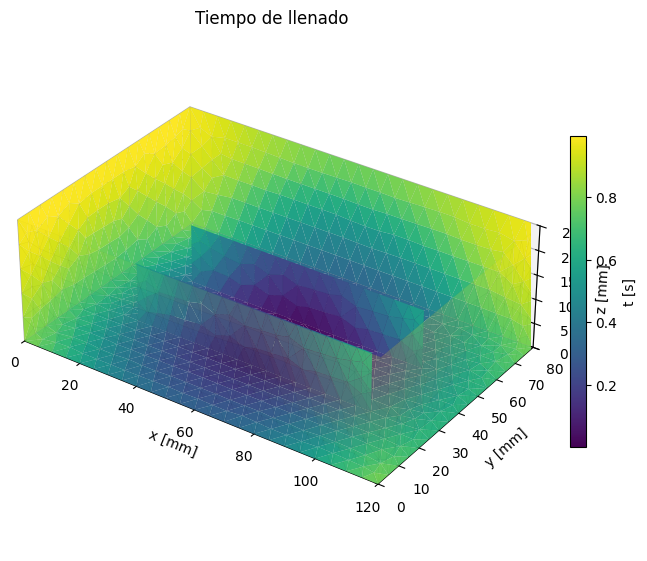

cuando llega y cuando termina el fundido en cada zona:
   pared x = 0   : llega a 0.677 s, termina a 0.999 s
   pared x = Lx  : llega a 0.640 s, termina a 0.999 s
   pared y = 0   : llega a 0.322 s, termina a 0.985 s
   pared y = Ly  : llega a 0.320 s, termina a 0.984 s
   nervios       : llega a 0.078 s, termina a 0.585 s
borde superior de las paredes: de 0.794 a 0.999 s (desequilibrio 0.205 s, 21% del llenado)


In [6]:
fig = plt.figure(figsize=(9, 5.5), constrained_layout=True)
ax = fig.add_subplot(projection='3d')
sm = draw_part(ax, element_values(ft), cmap='viridis', title='Tiempo de llenado')
fig.colorbar(sm, ax=ax, shrink=0.6, label='t [s]')
plt.show()

walls = {'pared x = 0': np.abs(xyz[:, 0]) < 1e-9, 'pared x = Lx': np.abs(xyz[:, 0] - Lx) < 1e-9,
         'pared y = 0': np.abs(xyz[:, 1]) < 1e-9, 'pared y = Ly': np.abs(xyz[:, 1] - Ly) < 1e-9}
rib_nodes = np.zeros(len(xyz), dtype=bool)
for yr in RIBS:
    rib_nodes |= (np.abs(xyz[:, 1] - yr) < 1e-9) & (xyz[:, 2] > 1e-9)
rim = np.abs(xyz[:, 2] - Lz) < 1e-9
print("cuando llega y cuando termina el fundido en cada zona:")
for name, nodes in list(walls.items()) + [('nervios', rib_nodes)]:
    print(f"   {name:14s}: llega a {np.nanmin(ft[nodes]):.3f} s, termina a {np.nanmax(ft[nodes]):.3f} s")
print(f"borde superior de las paredes: de {np.nanmin(ft[rim]):.3f} a {np.nanmax(ft[rim]):.3f} s "
      f"(desequilibrio {np.nanmax(ft[rim]) - np.nanmin(ft[rim]):.3f} s, {(np.nanmax(ft[rim]) - np.nanmin(ft[rim])) / fill.time:.0%} del llenado)")

## Líneas de soldadura y atrapamientos de aire

Una **línea de soldadura** aparece donde se encuentran dos frentes: el material que pasó por un lado de un obstáculo toca al que pasó por el otro.
Es una línea **material**: nace donde los frentes se tocan, detrás del agujero, y sigue hasta el final de la pieza, aunque el ángulo con que se
juntan se suavice. Es una zona más débil (las moléculas y las fibras no cruzan bien la unión) y a veces visible.

Se traza así: el camino de llenado de cada nodo se sigue hacia atrás, por el vecino que se llenó antes, hasta la entrada, y se cuenta cuánto gira
alrededor del centro del agujero. Dos nodos vecinos cuyos caminos rodean el agujero por lados opuestos (el lazo que forman da una vuelta) están a
ambos lados de la soldadura. La **calidad** de la unión depende de la temperatura del fundido al encontrarse: cuanto más caliente, mejor se funden
los frentes.

Un **atrapamiento de aire** es un punto que se llena después que todos sus vecinos: el aire no tiene por dónde salir. En el borde abierto de las
paredes (la línea de partición del molde) escapa por el venteo; un máximo local en otro sitio, como el extremo ciego de un nervio, necesita un
venteo propio (o un expulsor ajustado que deje salir el aire).

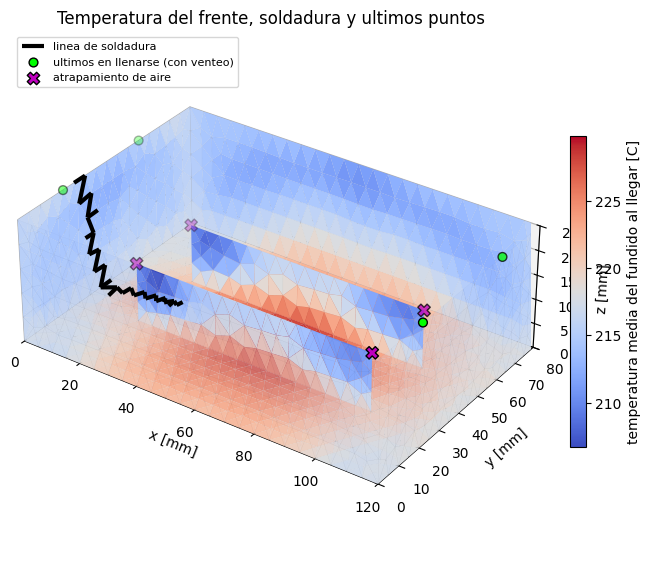

linea de soldadura: nace en (24.5, 42.3) mm a 0.299 s, detras del agujero; recorre la base hasta x = 0.0 mm y sube por la pared hasta z = 25.0 mm
temperatura del frente en la soldadura: 223.6 C donde nace, 212.6 C en el punto mas frio (fundido a 230 C, no flujo a 180.8 C)
ultimos puntos en llenarse: 8 (4 en el borde con venteo, 4 posibles atrapamientos)
   atrapamiento en (100.0, 27.0, 12.0) mm (nervio), llenado a 0.569 s
   atrapamiento en (20.0, 27.0, 12.0) mm (nervio), llenado a 0.585 s
   atrapamiento en (100.0, 53.0, 12.0) mm (nervio), llenado a 0.568 s
   atrapamiento en (20.0, 53.0, 12.0) mm (nervio), llenado a 0.581 s


In [7]:
disc = Discretization(mesh)
normal = np.cross(xyz[tris[:, 1]] - xyz[tris[:, 0]], xyz[tris[:, 2]] - xyz[tris[:, 0]])
normal /= np.linalg.norm(normal, axis=1, keepdims=True)
edge_owner = {}
for e, t in enumerate(tris):
    for a, b in ((t[0], t[1]), (t[1], t[2]), (t[2], t[0])):
        edge_owner.setdefault(tuple(sorted((int(a), int(b)))), []).append(e)
neighbours = [set() for _ in range(len(xyz))]
for a, b in edge_owner:
    neighbours[a].add(b); neighbours[b].add(a)
gate_nodes = set(np.unique(np.ravel(gate)).tolist())

# camino de llenado hacia atras y giro acumulado alrededor del centro del agujero (en el plano de la base)
theta = np.arctan2(xyz[:, 1] - HOLE[1], xyz[:, 0] - HOLE[0])
wrap = lambda d: (d + np.pi) % (2 * np.pi) - np.pi
turn, root = np.zeros(len(xyz)), np.arange(len(xyz))
for k in np.argsort(ft):
    if k in gate_nodes:
        continue
    j = min((j for j in neighbours[k] if ft[j] < ft[k]), key=lambda j: ft[j])
    turn[k], root[k] = turn[j] + wrap(theta[k] - theta[j]), root[j]
weld = np.array([(a, b) for a, b in edge_owner
                 if abs(turn[a] + wrap(theta[b] - theta[a]) - turn[b] + wrap(theta[root[b]] - theta[root[a]])) > np.pi])
weld_nodes = np.unique(weld)
birth = weld_nodes[np.argmin(ft[weld_nodes])]

last_fill = [k for k in range(len(xyz)) if k not in gate_nodes and all(ft[k] >= ft[j] for j in neighbours[k])]
traps = [k for k in last_fill if not rim[k]]

fig = plt.figure(figsize=(9, 5.5), constrained_layout=True)
ax = fig.add_subplot(projection='3d')
sm = draw_part(ax, element_values(front_T), cmap='coolwarm', title='Temperatura del frente, soldadura y ultimos puntos')
ax.add_collection3d(Line3DCollection(xyz[weld] * 1e3, colors='k', linewidths=3, label='linea de soldadura', zorder=10))
ax.scatter(*(xyz[[k for k in last_fill if rim[k]]].T * 1e3), color='lime', edgecolor='k', s=40, zorder=11,
           label='ultimos en llenarse (con venteo)')
if traps:
    ax.scatter(*(xyz[traps].T * 1e3), color='m', edgecolor='k', s=80, marker='X', zorder=11, label='atrapamiento de aire')
ax.legend(loc='upper left', fontsize=8)
fig.colorbar(sm, ax=ax, shrink=0.6, label='temperatura media del fundido al llegar [C]')
plt.show()

on_base = weld_nodes[xyz[weld_nodes, 2] < 1e-9]
on_wall = weld_nodes[xyz[weld_nodes, 2] > 1e-9]
print(f"linea de soldadura: nace en ({xyz[birth, 0] * 1e3:.1f}, {xyz[birth, 1] * 1e3:.1f}) mm a {ft[birth]:.3f} s, detras del agujero; "
      f"recorre la base hasta x = {xyz[on_base, 0].min() * 1e3:.1f} mm"
      + (f" y sube por la pared hasta z = {xyz[on_wall, 2].max() * 1e3:.1f} mm" if len(on_wall) else ""))
print(f"temperatura del frente en la soldadura: {np.nanmax(front_T[weld_nodes]):.1f} C donde nace, {np.nanmin(front_T[weld_nodes]):.1f} C en "
      f"el punto mas frio (fundido a {T_MELT:.0f} C, no flujo a {T_NOFLOW:.1f} C)")
print(f"ultimos puntos en llenarse: {len(last_fill)} ({len(last_fill) - len(traps)} en el borde con venteo, {len(traps)} posibles atrapamientos)")
for k in traps:
    print(f"   atrapamiento en ({xyz[k, 0] * 1e3:.1f}, {xyz[k, 1] * 1e3:.1f}, {xyz[k, 2] * 1e3:.1f}) mm ({zone_of_node(k)}), llenado a {ft[k]:.3f} s")

## Presión de inyección y fuerza de cierre

La presión de entrada crece a medida que aumenta el recorrido del fundido y la capa congelada estrecha el paso. Las marcas indican cuándo el
frente llega a cada zona. La **fuerza de cierre** que debe aguantar la máquina es la presión de la cavidad sobre el área proyectada en la
dirección de apertura del molde (aquí z): solo cuenta la base; las paredes y los nervios, verticales, no empujan en z.

El **esfuerzo cortante** en el borde del fundido, junto a la capa congelada, $\tau_w = (h_\text{fundido}/2)\,|\nabla p|$ con
$h_\text{fundido} = h\,(1 - f_\text{congelada})$, indica dónde trabaja más el material: valores altos orientan las fibras y pueden degradar el
polímero. Se toma el máximo a lo largo del llenado, solo donde hay fundido.

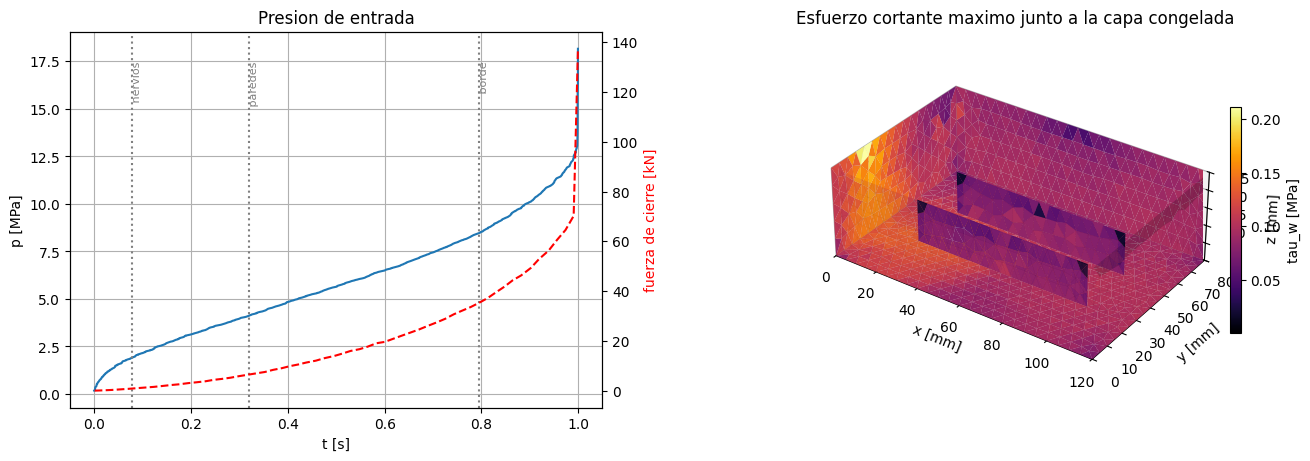

presion maxima de entrada 18.16 MPa; fuerza de cierre al final 137.4 kN (14.00 t), sobre 94.8 cm2 proyectados
esfuerzo cortante maximo en base  : 0.190 MPa
esfuerzo cortante maximo en pared : 0.211 MPa
esfuerzo cortante maximo en nervio: 0.106 MPa


In [8]:
area = 0.5 * np.linalg.norm(np.cross(xyz[tris[:, 1]] - xyz[tris[:, 0]], xyz[tris[:, 2]] - xyz[tris[:, 0]]), axis=1)
clamp = []
for fr in frames:
    pe = element_values(fr['p'])
    clamp.append(np.sum(pe * area * np.abs(normal[:, 2])))
clamp = np.array(clamp)
t_frames = np.array([fr['t'] for fr in frames])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
axes[0].plot(history[:, 0], history[:, 2] / 1e6, '-', label='presion de entrada')
for name, nodes in (('nervios', rib_nodes), ('paredes', np.any(np.stack(list(walls.values())), axis=0)), ('borde', rim)):
    t0 = np.nanmin(ft[nodes])
    axes[0].axvline(t0, ls=':', color='gray')
    axes[0].text(t0, axes[0].get_ylim()[1] * 0.92, f' {name}', rotation=90, va='top', fontsize=8, color='gray')
axes[0].set_xlabel('t [s]'); axes[0].set_ylabel('p [MPa]'); axes[0].grid(True); axes[0].set_title('Presion de entrada')
ax2 = axes[0].twinx()
ax2.plot(t_frames, clamp / 1e3, 'r--', label='fuerza de cierre')
ax2.set_ylabel('fuerza de cierre [kN]', color='r')
axes[1].remove()
ax3 = fig.add_subplot(1, 2, 2, projection='3d')
tau_w = np.zeros(len(tris))
for fr in frames:
    melt = element_values(fr['fill']) >= 0.999
    h_melt = h_elem * (1.0 - element_values(fr['frozen']))
    tau = 0.5 * h_melt * np.linalg.norm(disc.gradient(fr['p']).mean(axis=1), axis=1)
    tau_w = np.maximum(tau_w, np.where(melt, tau, 0.0))
sm = draw_part(ax3, tau_w / 1e6, cmap='inferno', title='Esfuerzo cortante maximo junto a la capa congelada')
fig.colorbar(sm, ax=ax3, shrink=0.6, label='tau_w [MPa]')
plt.show()
print(f"presion maxima de entrada {history[:, 2].max() / 1e6:.2f} MPa; fuerza de cierre al final {clamp[-1] / 1e3:.1f} kN "
      f"({clamp[-1] / 9.81e3:.2f} t), sobre {np.sum(area * np.abs(normal[:, 2])) * 1e4:.1f} cm2 proyectados")
for name in ('base', 'pared', 'nervio'):
    print(f"esfuerzo cortante maximo en {name:6s}: {tau_w[zone == name].max() / 1e6:.3f} MPa")

## Animación 2: enfriamiento y capa congelada

Mientras llena, el fundido pierde calor contra el molde. A la izquierda, la temperatura media en el espesor; a la derecha, la fracción del espesor
ya congelada. La capa congelada es mayor cerca de la entrada (lleva más tiempo en contacto con el molde) y en las zonas delgadas (nervios),
que se enfrían antes. También se guarda como `enfriamiento_pieza_3d.gif`.

In [9]:
T_norm = plt.Normalize(T_NOFLOW - 10, T_MELT)
f_norm = plt.Normalize(0.0, 1.0)
fig = plt.figure(figsize=(11, 4.4), dpi=64)
axL = fig.add_subplot(1, 2, 1, projection='3d')
axR = fig.add_subplot(1, 2, 2, projection='3d')
fig.colorbar(plt.cm.ScalarMappable(norm=T_norm, cmap='coolwarm'), ax=axL, shrink=0.55, label='T media [C]')
fig.colorbar(plt.cm.ScalarMappable(norm=f_norm, cmap='Blues'), ax=axR, shrink=0.55, label='fraccion congelada')


def draw_thermal(k):
    fr = frames[k]
    empty = element_values(fr['fill']) < 0.999
    axL.clear(); axR.clear()
    draw_part(axL, element_values(fr['T']), cmap='coolwarm', norm=T_norm, empty=empty, title=f"T media, t = {fr['t']:.3f} s")
    draw_part(axR, element_values(fr['frozen']), cmap='Blues', norm=f_norm, empty=empty, title='capa congelada')
    return []


movie2 = animation.FuncAnimation(fig, draw_thermal, frames=len(frames), interval=120)
movie2.save('enfriamiento_pieza_3d.gif', writer=animation.PillowWriter(fps=8), dpi=60)
light2 = animation.FuncAnimation(fig, lambda k: draw_thermal(index[k]), frames=len(index), interval=200)
html2 = light2.to_jshtml(default_mode='once')
plt.close(fig)
HTML(html2)

## Perfiles de temperatura en el espesor

Cada nodo lleva el perfil $T(z)$ del plano medio ($z/b = 0$) a la pared ($z/b = 1$). Junto a la pared el fundido está casi a la temperatura del
molde; en el centro, caliente. El **calentamiento viscoso** (el corte disipa energía) puede subir la temperatura por encima de la de entrada
justo bajo la capa congelada, donde el corte es mayor.

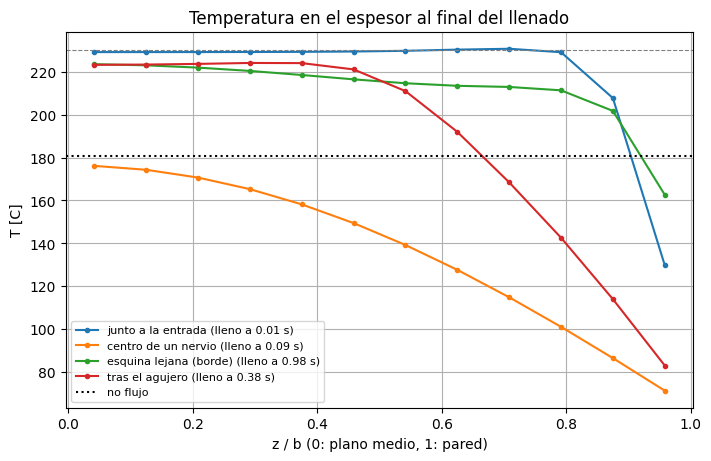

In [10]:
edges = fill.thermal['edges']
zc = 0.5 * (edges[:-1] + edges[1:])
probes = {'junto a la entrada': (GATE[0] + 0.006, GATE[1], 0.0), 'centro de un nervio': (0.06, RIBS[0], RIB_H / 2),
          'esquina lejana (borde)': (Lx, Ly, Lz), 'tras el agujero': (HOLE[0] - HOLE[2] - 0.004, HOLE[1], 0.0)}
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
for name, point in probes.items():
    k = int(np.argmin(np.linalg.norm(xyz - np.array(point), axis=1)))
    ax.plot(zc, fill.T[k], 'o-', ms=3, label=f"{name} (lleno a {ft[k]:.2f} s)")
ax.axhline(T_NOFLOW, ls=':', color='k', label='no flujo')
ax.axhline(T_MELT, ls='--', color='gray', lw=0.8)
ax.set_xlabel('z / b (0: plano medio, 1: pared)'); ax.set_ylabel('T [C]'); ax.grid(True); ax.legend(fontsize=8)
ax.set_title('Temperatura en el espesor al final del llenado')
plt.show()

## Ventana de proceso: el tiempo de llenado

¿Cuánto debe tardar el llenado? Rápido exige más presión para empujar el caudal; lento deja que la capa congelada crezca y cierre el paso, y la
presión vuelve a subir. Entre ambos hay un **mínimo de presión** (la curva en U de la inyección). Un llenado isotermo no ve la rama lenta: su
presión solo baja al llenar más despacio. Se repite el llenado con varios tiempos, con una malla algo más gruesa (7 mm) para que tarde poco.

In [11]:
gmsh.initialize()
gmsh.option.setNumber("General.Terminal", 0)
try:
    occ = gmsh.model.occ
    box = occ.addBox(0, 0, 0, Lx, Ly, Lz)
    occ.synchronize()
    faces = [t for _, t in gmsh.model.getEntities(2)]
    lid = [s for s in faces if abs(occ.getCenterOfMass(2, s)[2] - Lz) < 1e-12]
    base = [s for s in faces if abs(occ.getCenterOfMass(2, s)[2]) < 1e-12][0]
    occ.remove([(3, box)]); occ.remove([(2, s) for s in lid])
    occ.cut([(2, base)], [(2, occ.addDisk(x, y, 0, r, r)) for x, y, r in (GATE, HOLE)])
    for y in RIBS:
        rib = occ.addRectangle(RIB_X0, 0.0, 0.0, RIB_X1 - RIB_X0, RIB_H)
        occ.rotate([(2, rib)], 0, 0, 0, 1, 0, 0, np.pi / 2); occ.translate([(2, rib)], 0, y, 0)
    occ.synchronize()
    occ.fragment([(2, t) for _, t in gmsh.model.getEntities(2)], [])
    occ.synchronize()
    gmsh.option.setNumber('Mesh.MeshSizeMax', 7e-3); gmsh.option.setNumber('Mesh.MeshSizeMin', 7e-3 / 3)
    gmsh.option.setNumber('Mesh.MeshSizeFromCurvature', 16)
    gmsh.model.mesh.generate(2)
    coarse = Mesh.from_gmsh_model(surface=True)
finally:
    gmsh.finalize()
coarse_gate = coarse.boundary_facets(lambda x, y, z: z < 1e-9 and np.hypot(x - GATE[0], y - GATE[1]) < GATE[2] + 1e-6)


def run(fill_time, thermal):
    f = HeleShawFilling(coarse, gap, LAW, T=T_MELT)
    if thermal:
        f.setThermal(T_MELT, T_MOLD, RHO, CP, K, htc=HTC, T_noflow=T_NOFLOW, cells=12)
    f.addGate(coarse_gate, float(f.volume.sum()) / fill_time)
    f.fill(progress=False)
    return f


sweep = {}
start = time.perf_counter()
for t_fill in (0.3, 0.5, 1.0, 2.0, 4.0, 6.0):
    hot, iso = run(t_fill, True), run(t_fill, False)
    sweep[t_fill] = dict(p=hot.history[-1][2], p_iso=iso.history[-1][2], frozen=hot.frozen_fraction().mean(), short=hot.short_shot,
                         filled=hot.melt_volume() / float(hot.volume.sum()))
    print(f"   llenado en {t_fill:.1f} s: p {sweep[t_fill]['p'] / 1e6:6.2f} MPa (isotermo {sweep[t_fill]['p_iso'] / 1e6:6.2f}), "
          f"capa congelada {sweep[t_fill]['frozen']:.0%}"
          + (f", TIRO CORTO con {sweep[t_fill]['filled']:.0%} lleno" if sweep[t_fill]['short'] else "")
          + f"  [{time.perf_counter() - start:.0f} s]", flush=True)

   llenado en 0.3 s: p  18.08 MPa (isotermo  13.92), capa congelada 14%  [97 s]
   llenado en 0.5 s: p  17.63 MPa (isotermo  12.13), capa congelada 19%  [190 s]
   llenado en 1.0 s: p  18.26 MPa (isotermo  10.04), capa congelada 30%  [281 s]
   llenado en 2.0 s: p  22.16 MPa (isotermo   8.27), capa congelada 44%  [369 s]
   tiro corto a t = 3.942 s: ningun nodo recibe fundido (la capa congelada cerro el paso)
   llenado en 4.0 s: p  73.25 MPa (isotermo   6.76), capa congelada 65%, TIRO CORTO con 99% lleno  [453 s]
   tiro corto a t = 5.774 s: ningun nodo recibe fundido (la capa congelada cerro el paso)
   llenado en 6.0 s: p  69.07 MPa (isotermo   5.94), capa congelada 75%, TIRO CORTO con 96% lleno  [532 s]


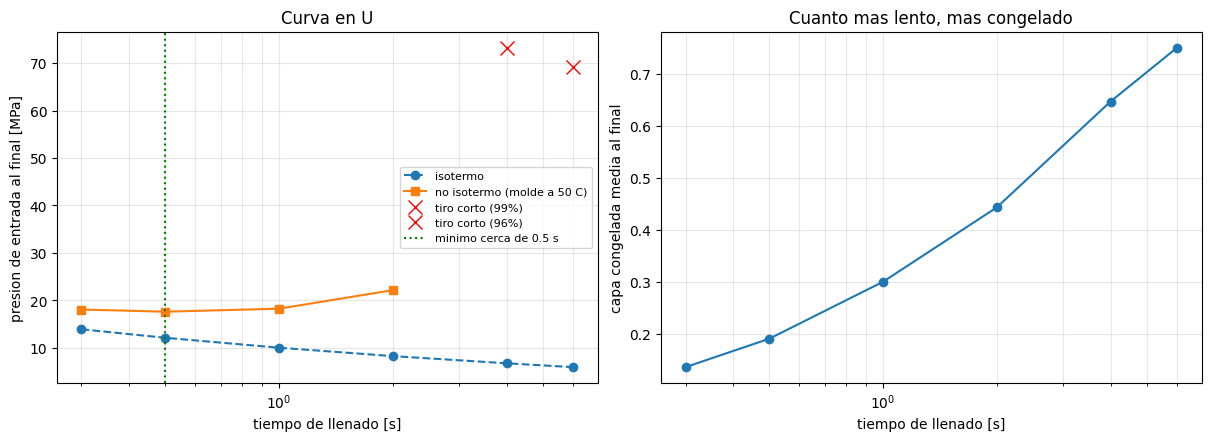

In [12]:
times = np.array(sorted(sweep))
full = np.array([sweep[t]['short'] is None for t in times])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
axes[0].plot(times, [sweep[t]['p_iso'] / 1e6 for t in times], 'o--', label='isotermo')
axes[0].plot(times[full], [sweep[t]['p'] / 1e6 for t in times[full]], 's-', label=f'no isotermo (molde a {T_MOLD:.0f} C)')
for t in times[~full]:
    axes[0].plot(t, sweep[t]['p'] / 1e6, 'rx', ms=10, label=f"tiro corto ({sweep[t]['filled']:.0%})")
best = times[full][np.argmin([sweep[t]['p'] for t in times[full]])]
axes[0].axvline(best, color='g', ls=':', label=f'minimo cerca de {best:.1f} s')
axes[0].set_xscale('log'); axes[0].set_xlabel('tiempo de llenado [s]'); axes[0].set_ylabel('presion de entrada al final [MPa]')
axes[0].grid(True, which='both', alpha=0.3); axes[0].legend(fontsize=8); axes[0].set_title('Curva en U')
axes[1].plot(times, [sweep[t]['frozen'] for t in times], 'o-')
axes[1].set_xscale('log'); axes[1].set_xlabel('tiempo de llenado [s]'); axes[1].set_ylabel('capa congelada media al final')
axes[1].grid(True, which='both', alpha=0.3); axes[1].set_title('Cuanto mas lento, mas congelado')
plt.show()

In [13]:
frozen_end = fill.frozen_fraction()
rows = [('tiempo de llenado', f"{fill.time:.3f} s"), ('presion de entrada al final', f"{history[-1, 2] / 1e6:.2f} MPa"),
        ('fuerza de cierre al final', f"{clamp[-1] / 1e3:.0f} kN ({clamp[-1] / 9.81e3:.1f} t)"),
        ('desequilibrio en el borde', f"{np.nanmax(ft[rim]) - np.nanmin(ft[rim]):.3f} s"),
        ('soldadura: nace a', f"{ft[birth]:.3f} s, frente entre {np.nanmin(front_T[weld_nodes]):.0f} y {np.nanmax(front_T[weld_nodes]):.0f} C"),
        ('posibles atrapamientos', f"{len(traps)} ({', '.join(sorted({zone_of_node(k) for k in traps})) or 'ninguno'})"),
        ('capa congelada media al final', f"{frozen_end.mean():.0%}"),
        ('  en la base / paredes / nervios', ' / '.join(f"{frozen_end[[zone_of_node(k) == z for k in range(len(xyz))]].mean():.0%}"
                                                           for z in ('base', 'pared', 'nervio'))),
        ('minimo de la curva en U', f"cerca de {best:.1f} s"),
        ('tiro corto si el llenado dura', ', '.join(f"{t:.0f} s" for t in times[~full]) or 'ninguno de los probados')]
for name, value in rows:
    print(f"{name:34s} {value}")

tiempo de llenado                  0.999 s
presion de entrada al final        18.16 MPa
fuerza de cierre al final          137 kN (14.0 t)
desequilibrio en el borde          0.205 s
soldadura: nace a                  0.299 s, frente entre 213 y 224 C
posibles atrapamientos             4 (nervio)
capa congelada media al final      31%
  en la base / paredes / nervios   28% / 24% / 80%
minimo de la curva en U            cerca de 0.5 s
tiro corto si el llenado dura      4 s, 6 s


## Conclusiones del análisis

Con los números de la tabla anterior (malla de 5 mm, refinada en el agujero y la entrada; llenado objetivo de 1 s):

1. **Patrón de llenado.** La entrada central llena la base en forma radial. Los nervios, junto a la entrada, se llenan pronto (de 0.08 a
   0.59 s); las paredes largas reciben el fundido a 0.32 s y las cortas a 0.64–0.68 s. El borde superior termina entre 0.79 y 1.00 s: un
   **desequilibrio de 0.21 s** (21 % del llenado), con las esquinas de las paredes cortas al final. Mover la entrada o repartirla en dos
   reduciría ese desequilibrio; no se ha simulado aquí.
2. **Línea de soldadura.** Nace detrás del agujero a 0.30 s, recorre la base hasta la pared x = 0 y sube por ella hasta el borde. El frente llega
   entre 213 y 224 °C, más de 30 °C sobre la temperatura de no flujo: una soldadura caliente, en principio de buena calidad. Pero queda en una
   pared visible; si eso importa, conviene mover el agujero o la entrada.
3. **Aire.** Las cuatro esquinas superiores de los nervios son los últimos puntos de su zona y no tienen salida: necesitan **venteo** (o un
   expulsor que deje escapar el aire). Los últimos puntos del borde de las paredes ventean por la línea de partición.
4. **Presión y máquina.** La presión de entrada llega a 18.2 MPa al final del llenado, con una subida marcada en el último 2–3 % del tiempo,
   cuando el fundido termina las esquinas por pasos ya estrechados por la capa congelada: ese valor final es el más sensible a la malla y a
   los datos térmicos. La **fuerza de cierre** al final del llenado es de unos 137 kN (14 t); la compactación la subirá (no se ha simulado aquí).
5. **Enfriamiento.** Al final del llenado está congelado el 31 % del espesor en promedio, pero el **80 % en los nervios**: el nervio de 1.2 mm
   está prácticamente congelado en todo su espesor (su centro, a unos 176 °C, ya está bajo la temperatura de no flujo). No podrá compactarse
   y contraerá de forma distinta que la base: riesgo de rechupes en la base frente a los nervios y de alabeo. Nervios algo más gruesos, o una
   entrada que los alcance más tarde con el fundido más caliente, lo aliviarían.
6. **Ventana de proceso.** La presión tiene un **mínimo cerca de 0.5 s** (17.6 MPa) y cambia poco entre 0.3 y 1 s (17.6 a 18.3 MPa). A 2 s
   sube a 22 MPa con el 44 % del espesor congelado, y con 4 y 6 s hay **tiro corto**: la capa congelada cierra el paso antes de llenar. El
   modelo isotermo predice lo contrario, una presión que solo baja al llenar más despacio: sin la temperatura no se ve el límite lento de la
   ventana. Un llenado de 0.5 a 1 s es razonable para esta pieza.

**Cautelas.** Es un modelo de plano medio (sin flujo a través del espesor), con un material real pero con temperatura de no flujo y coeficiente
de contacto supuestos, y sin medidas de esta pieza: las tendencias y la ubicación de soldaduras, aire y zonas congeladas son lo más fiable; los
valores absolutos de presión y fuerza, lo menos.

**Siguientes pasos posibles** con el mismo módulo: la compactación con la ecuación de Tait y la contracción volumétrica (`setDensity`, `pack`,
`shrinkage`, ver `Example_Packing_HeleShaw.py`), la cristalización (`setCrystallization`), un estudio de malla, y comparar otras posiciones de
la entrada.